# SBP 3D full-tilt analysis

Measured S22 is restricted to 20–22 GHz and used without an additive template correction. All 17 geometry parameters have been refitted on 35 quality-selected frequencies, then evaluated on the dense 401-bin grid. Each incident Gaussian is centred on the disk axis (x = y = 0), with its measured amplitude and width retained. The measured curved disk faces are included in the same coordinate frame, with measured disks 2, 3, 1 assigned to D1–D3. The nominal mirror–D1 reference-plane gap is 7.803 mm. Bands are conditional; several fitted coordinates reach their bounds. [Details](README.md#3d-analysis-with-disk-and-thread-tilts).

### Plot labels and exports

Edit text keywords in each plot cell; rerun to update its PNG/PDF exports under `plots/3d/full_tilt/`. Templates retain plotted values.

In [1]:
%matplotlib inline
from pathlib import Path
import json
import numpy as np
from src import analysis_3d_plots as plots
from src import analysis_3d_diagnostics as diagnostics
from src import pipeline_plots as measurement_plots

measurement_plots.configure_style()
DATA = Path("data/3d")
RUN_DIR = Path("data/spider_bead_pull_runs/run_20261025_141003")
# Maximum of the saved spider 3D boost curve over 20–22 GHz (beta2_conditional).
FREQUENCY_GHZ = 20.825  # Hard-coded sampled peak: beta² = 493.640.
plots.FREQUENCIES = (FREQUENCY_GHZ,)
plots.TITLE = "Disk tilts + sloped threads"
PLOT_ROOT = Path("plots")
FIGURE_DIR = PLOT_ROOT / "3d" / "full_tilt"

result = plots.load(DATA / "disk_tilts_threads.npz")
bands = plots.load(DATA / "conditional_bands.npz")
maps = plots.load(DATA / "field_maps.npz")
geometry = json.loads(Path("config/full_tilt_geometry.json").read_text())
profile_inputs = plots.load(DATA / "measurement_inputs.npz")
measurement = measurement_plots.load_measurement(RUN_DIR)

## 1. Conditional boost factor

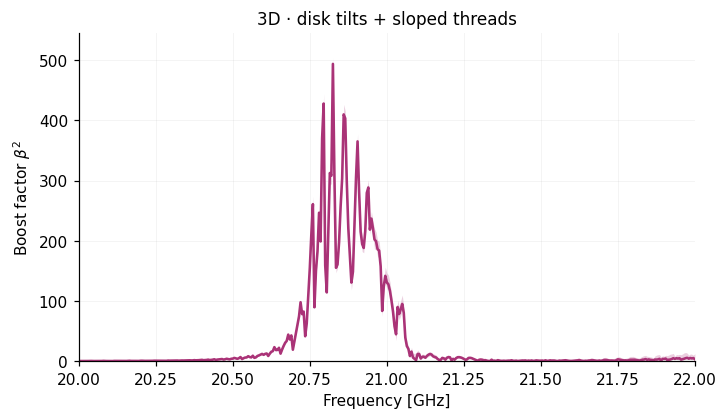

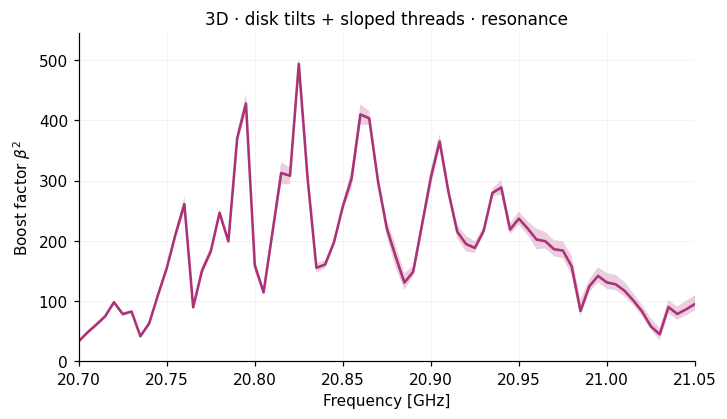

In [2]:
plots.present(
    plots.boost_figures(
        result, bands,
        title_template='3D · {case_title_lower}{zoom_suffix}',
        x_label='Frequency [GHz]',
        y_label='Boost factor $\\beta^2$',
    ),
    FIGURE_DIR / 'boost',
)

## 2. Measurement data

### Raw reflection spectra

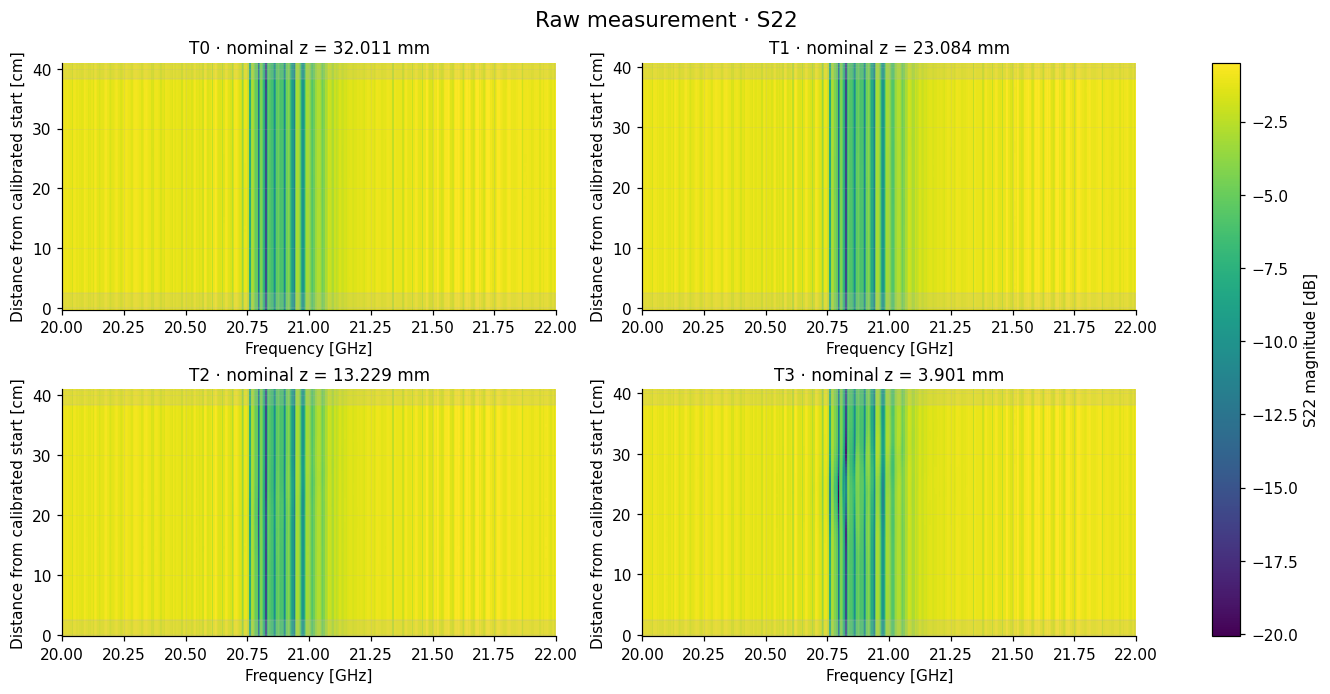

In [3]:
measurement_plots.present(
    measurement_plots.plot_measurement_map(
        measurement,
        title='Raw measurement · {s_parameter}',
        panel_title_template='T{thread_index} · nominal z = {z_mm:.3f} mm',
        x_label='Frequency [GHz]', y_label='Distance from calibrated start [cm]',
        colorbar_label='{s_parameter} magnitude [dB]',
    ),
    'raw_measurement_map', FIGURE_DIR / 'measurement/raw',
)

### Raw reflection magnitude

All 330 raw samples at 20.795 GHz, with a common dB scale.

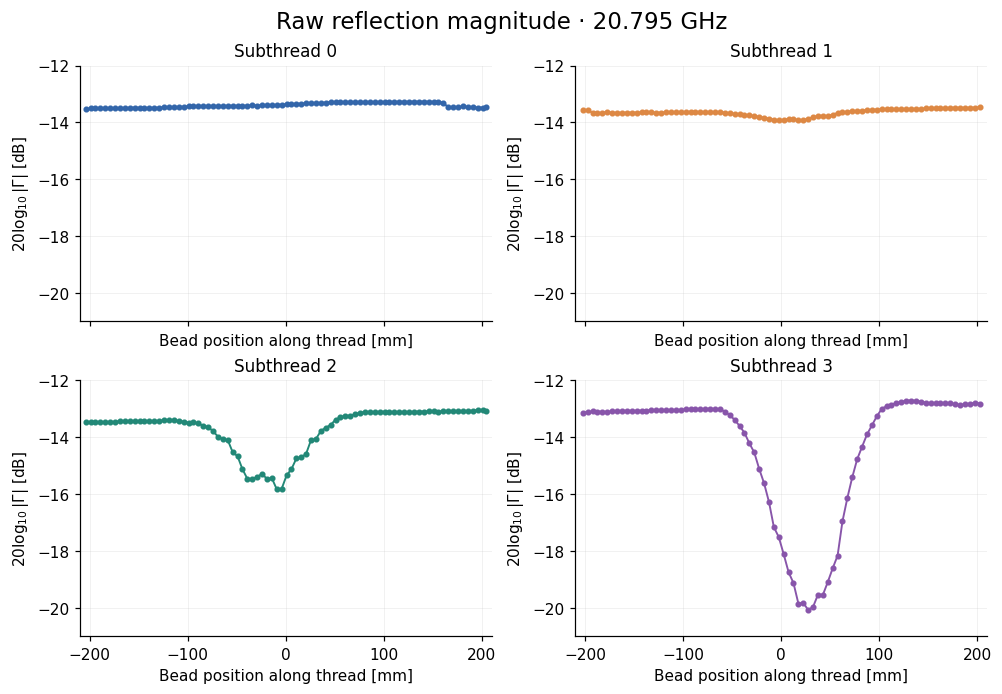

In [ ]:
measurement_plots.present(
    measurement_plots.plot_raw_magnitude(
        measurement, 20.795,
        title='Raw reflection magnitude at {frequency_GHz:.3f} GHz',
        panel_title_template='Thread {thread_index}',
        x_label='Bead position along thread [mm]',
        y_label=r'$20\log_{10}|\Gamma|$ [dB]',
    ),
    'raw_s11_magnitude_resonance', FIGURE_DIR / 'measurement/raw',
)

### Complex raw traces

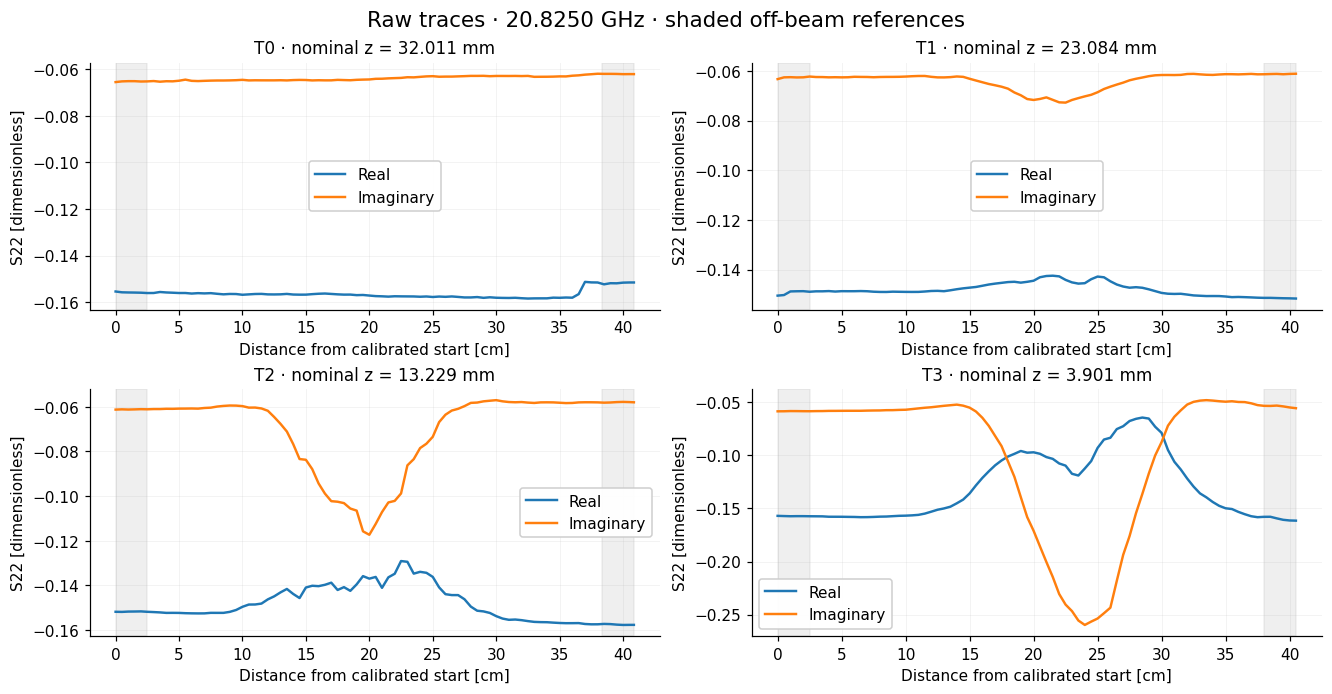

In [5]:
measurement_plots.present(
    measurement_plots.plot_raw_traces(
        measurement, FREQUENCY_GHZ,
        title='Raw traces · {frequency_GHz:.4f} GHz · shaded off-beam references',
        panel_title_template='T{thread_index} · nominal z = {z_mm:.3f} mm',
        x_label='Distance from calibrated start [cm]',
        y_label='{s_parameter} [dimensionless]',
        real_label='Real',
        imaginary_label='Imaginary',
    ),
    "raw_complex_traces", FIGURE_DIR / "measurement/raw",
)

## 3. Incident beam

Each of the six fitted Gaussian magnitude profiles is centred on the common disk axis (x = y = 0), retaining its measured amplitude and width. Their sum is supplied at the model’s outer reference face with flat phase and whole-plane power 1 W. Beam alignment is fixed during the geometry fit; the scan z origin is not registered to the mirror.

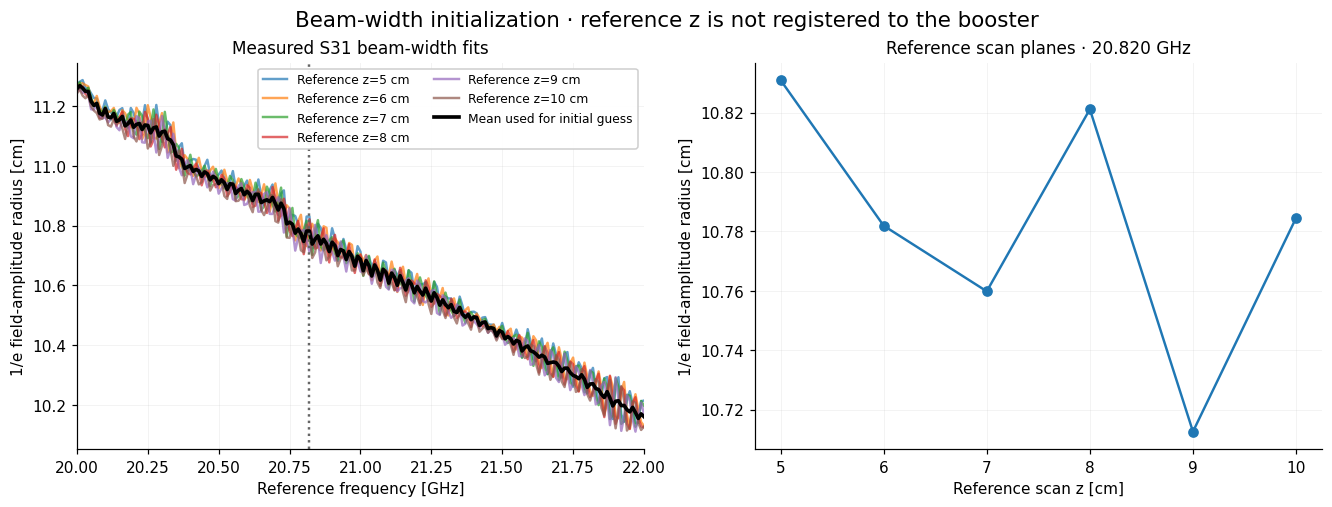

In [6]:
measurement_plots.present(
    measurement_plots.plot_beam_reference(
        measurement, FREQUENCY_GHZ,
        title='Beam-width initialization · reference z is not registered to the booster',
        spectrum_title='Measured S31 beam-width fits',
        planes_title='Reference scan planes · {frequency_GHz:.3f} GHz',
        frequency_x_label='Reference frequency [GHz]',
        position_x_label='Reference scan z [cm]',
        y_label='1/e field-amplitude radius [cm]',
        reference_label_template='Reference z={z_cm:.0f} cm',
        mean_label='Mean used for initial guess',
    ),
    "incident_beam_widths", FIGURE_DIR / "measurement/incident_beam",
)

### Actual input profile

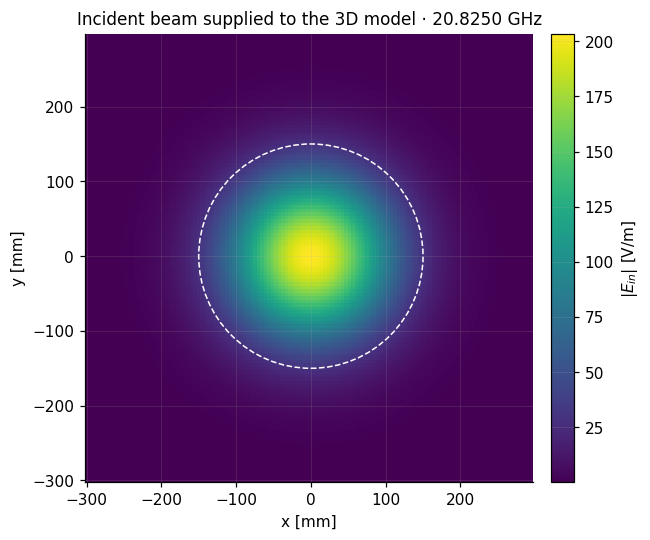

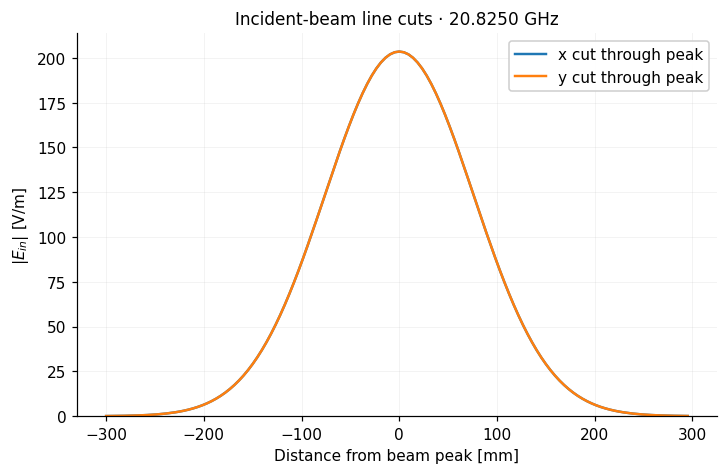

In [7]:
from src.analysis_3d_exports import incident_beam_profile

incident_profile = incident_beam_profile(DATA / 'bank', DATA / 'beam_prior.npz', FREQUENCY_GHZ)
plots.present(
    diagnostics.incident_beam_figures(
        incident_profile,
        title='Incident beam supplied to the 3D model · {frequency_GHz:.4f} GHz',
        cuts_title='Incident-beam line cuts · {frequency_GHz:.4f} GHz',
        x_label='x [mm]', y_label='y [mm]', colorbar_label='$|E_{in}|$ [V/m]',
        cut_x_label='Distance from beam peak [mm]', cut_y_label='$|E_{in}|$ [V/m]',
        x_cut_label='x cut through peak', y_cut_label='y cut through peak',
    ),
    FIGURE_DIR / 'measurement/incident_beam',
)

## 4. Frequency selection

Preliminary Gaussian fits select frequencies; they do not supply the field fitted by the 3D model.

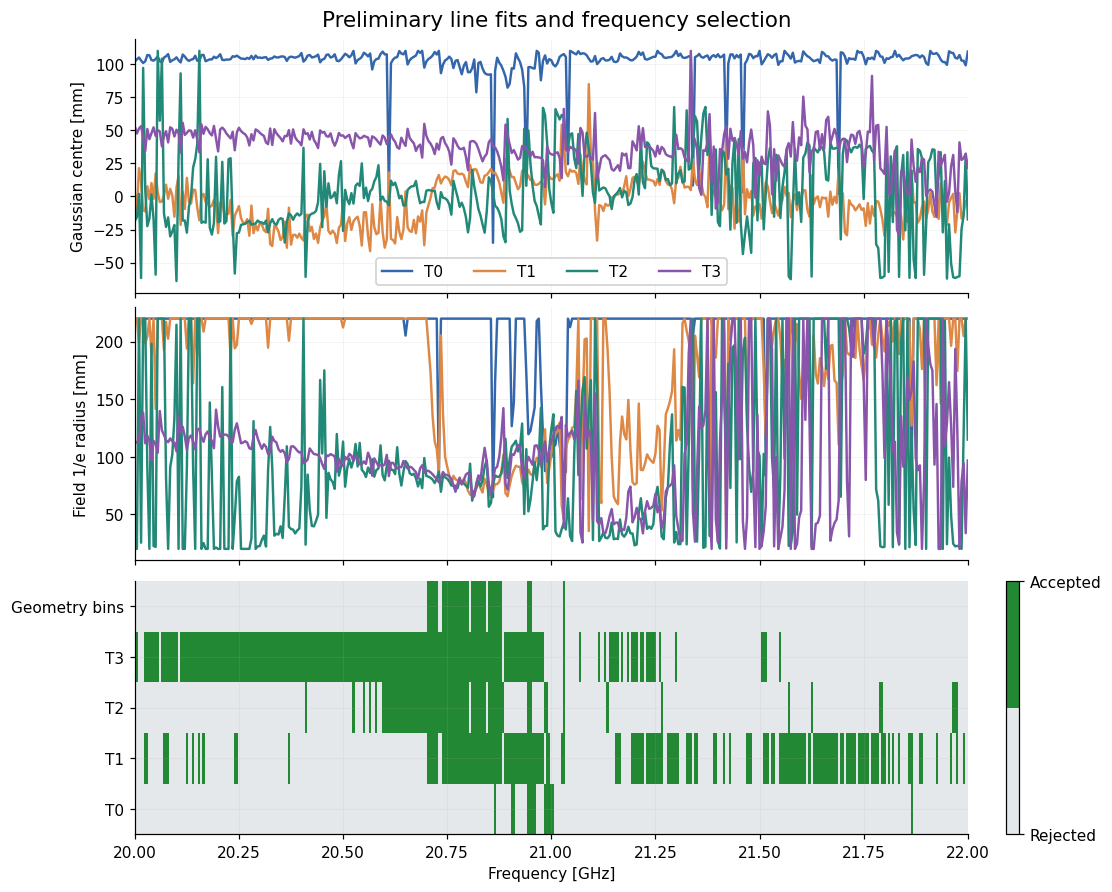

In [8]:
plots.present(
    diagnostics.profile_quality_figure(
        profile_inputs,
        title='Preliminary line fits and frequency selection',
        x_label='Frequency [GHz]', center_y_label='Gaussian centre [mm]',
        width_y_label='Field 1/e radius [mm]', thread_label_template='T{thread_index}',
        selection_label='Geometry bins', rejected_label='Rejected', accepted_label='Accepted',
    ),
    FIGURE_DIR / 'measurement/profile_quality',
)

## 5. Complex reflection fits

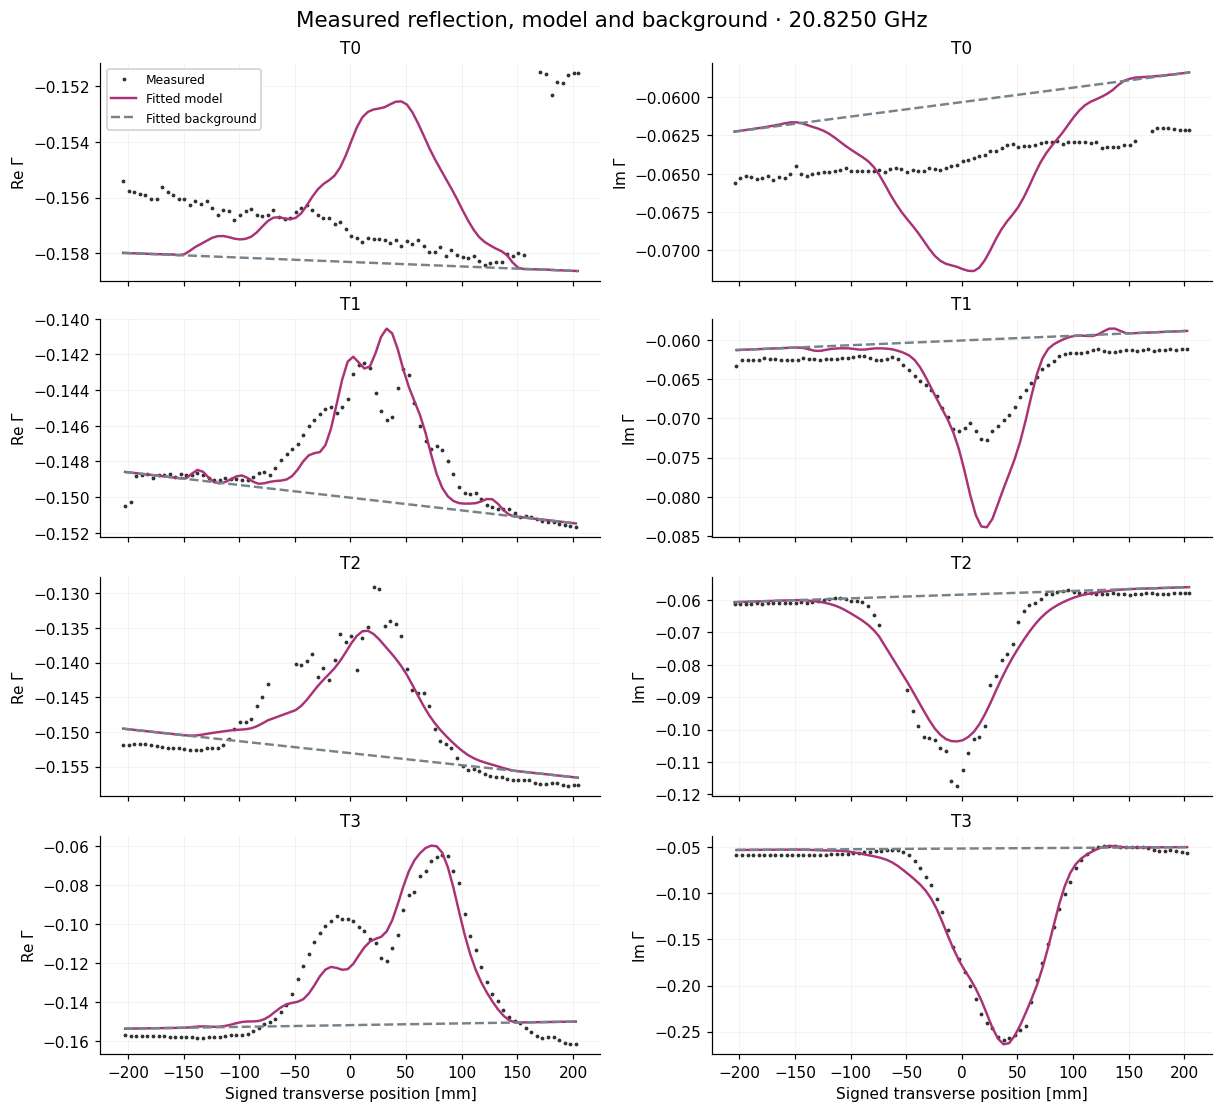

In [9]:
plots.present(
    diagnostics.raw_fit_figure(
        result, FREQUENCY_GHZ,
        title='Measured reflection, model and background · {frequency_GHz:.4f} GHz',
        x_label='Signed transverse position [mm]', real_y_label=r'Re $\Gamma$',
        imaginary_y_label=r'Im $\Gamma$', thread_label_template='T{thread_index}',
        measured_label='Measured', model_label='Fitted model', background_label='Fitted background',
    ),
    FIGURE_DIR / 'profiles/raw_reflection',
)

### After the fitted background subtraction

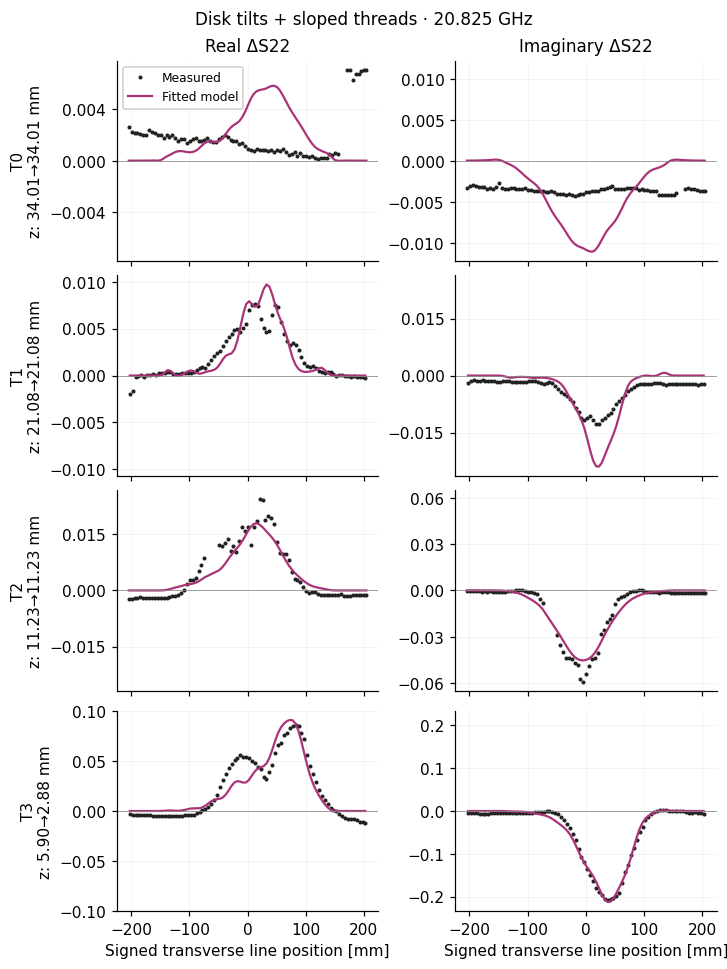

In [10]:
plots.present(
    plots.profile_figures(
        result,
        title_template='{case_title} · {frequency_GHz:.3f} GHz',
        real_component_label='Real ΔS22',
        imaginary_component_label='Imaginary ΔS22',
        x_label='Signed transverse line position [mm]',
        thread_label_template='T{thread_index}{held_out}\nz: {z_start_mm:.2f}→{z_end_mm:.2f} mm',
        measured_label='Measured',
        model_label='Fitted model',
        held_out_label=' · held out',
    ),
    FIGURE_DIR / 'profiles',
)

### Complex-plane trajectories

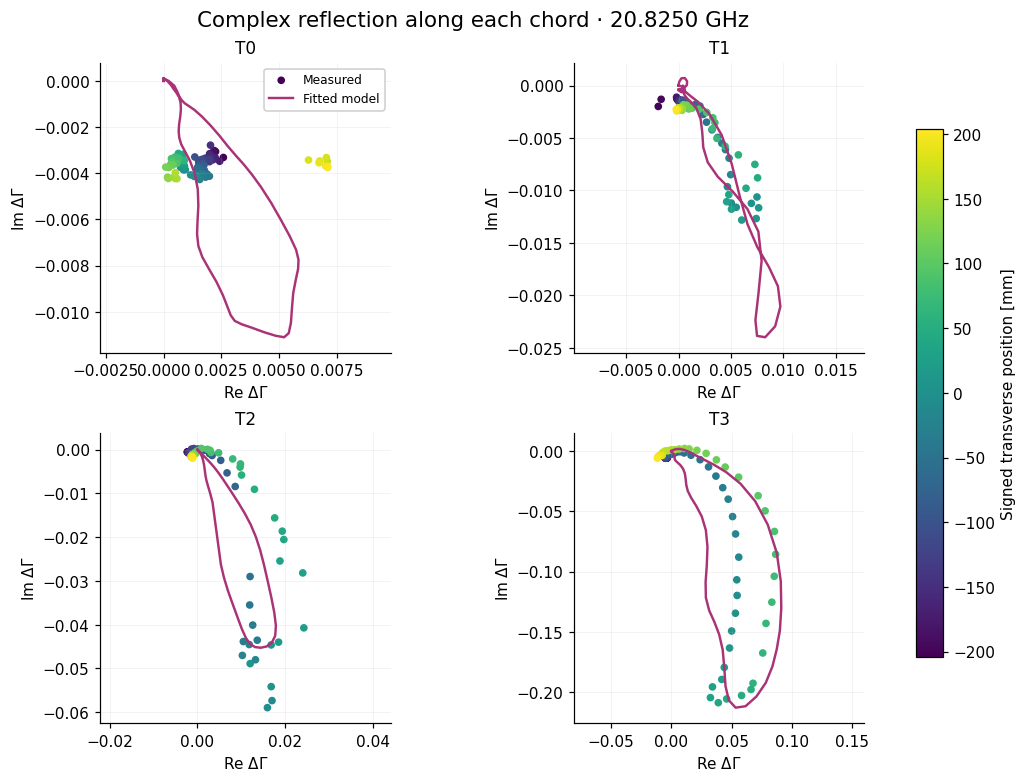

In [11]:
plots.present(
    diagnostics.complex_plane_figure(
        result, FREQUENCY_GHZ,
        title='Complex reflection along each chord · {frequency_GHz:.4f} GHz',
        x_label=r'Re $\Delta\Gamma$', y_label=r'Im $\Delta\Gamma$',
        colorbar_label='Signed transverse position [mm]', thread_label_template='T{thread_index}',
        measured_label='Measured', model_label='Fitted model',
    ),
    FIGURE_DIR / 'profiles/complex_plane',
)

## 6. Fields

Finite-bead field estimates and the model electric field are shown separately.

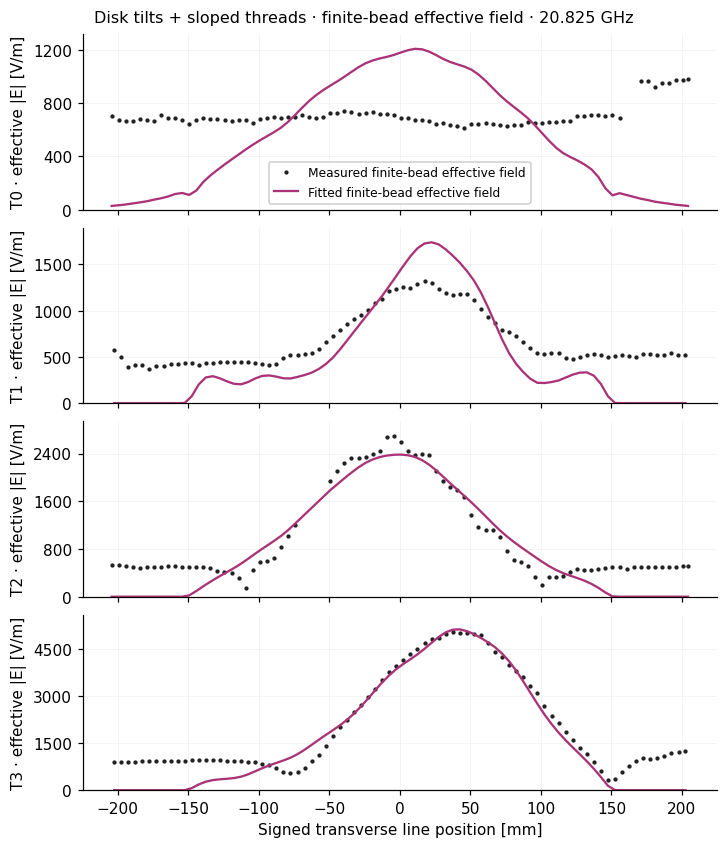

In [ ]:
field_figures, _ = plots.effective_field_figures(
    result,
        title_template='{case_title} · finite-bead effective field · {frequency_GHz:.3f} GHz',
        x_label='Signed transverse line position [mm]',
        y_label_template='T{thread_index}{held_out} · |E| [V/m]',
        measured_label='Measured finite-bead effective field',
        model_label='Fitted finite-bead effective field',
        held_out_label=' · held out',
)
plots.present(field_figures, FIGURE_DIR / "fields/chords")

### Measured and fitted finite-bead spectra

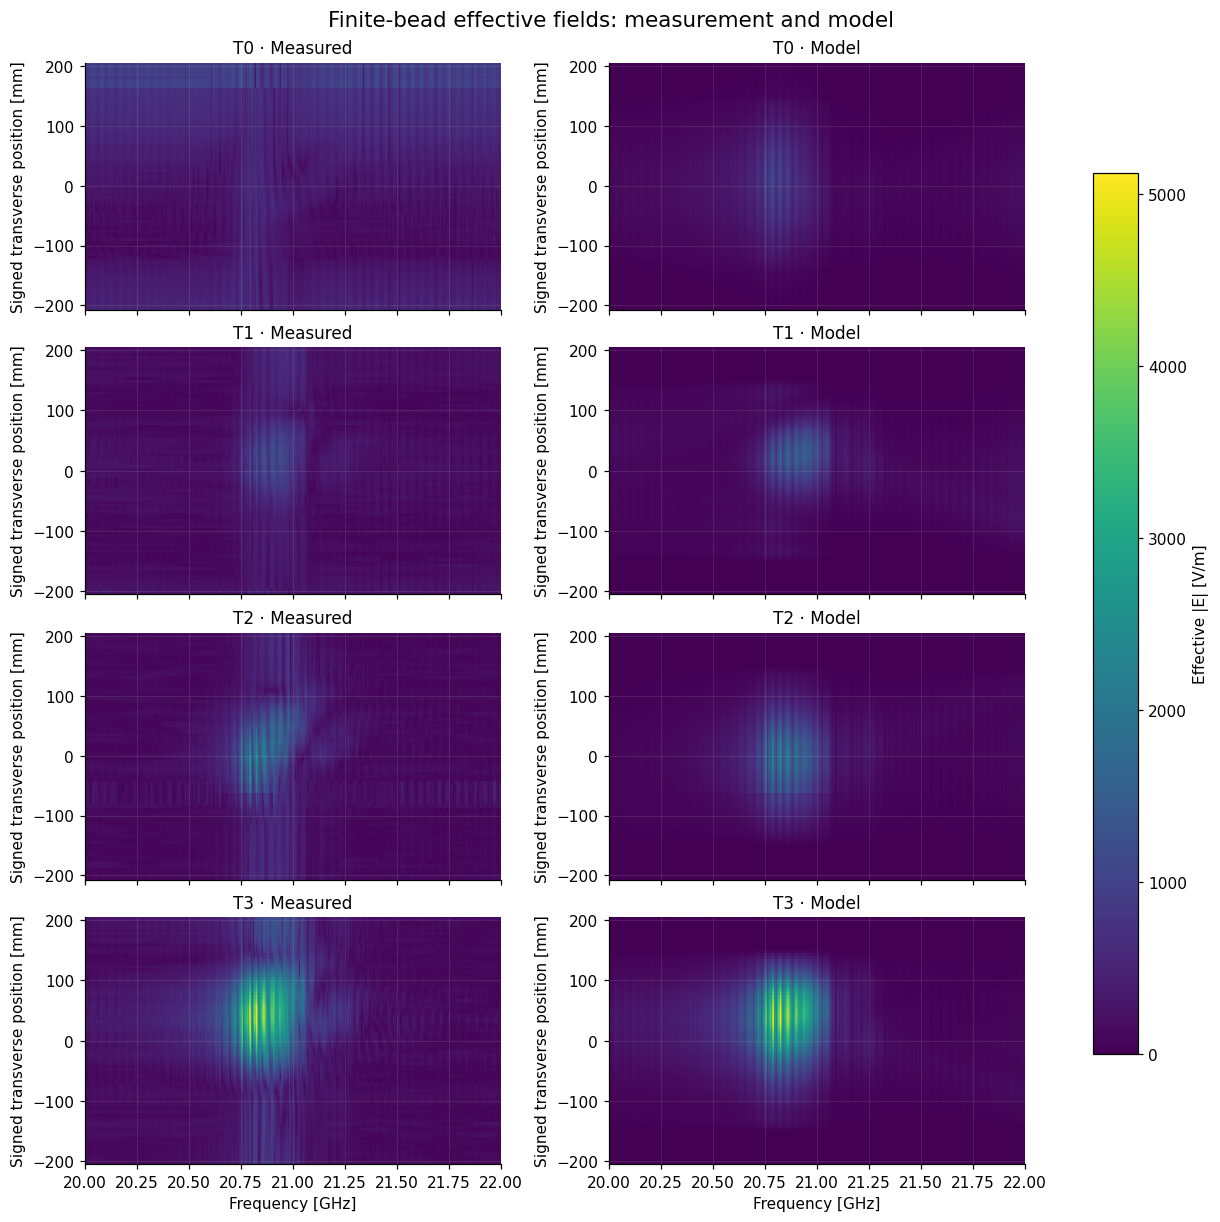

In [13]:
plots.present(
    diagnostics.effective_spectrum_figure(
        result,
        title='Finite-bead effective fields: measurement and model',
        x_label='Frequency [GHz]', y_label='Signed transverse position [mm]',
        colorbar_label='Effective |E| [V/m]', measured_label='Measured', model_label='Model',
        thread_label_template='T{thread_index}',
    ),
    FIGURE_DIR / 'fields/finite_bead',
)

### Directional fields on the sloped paths

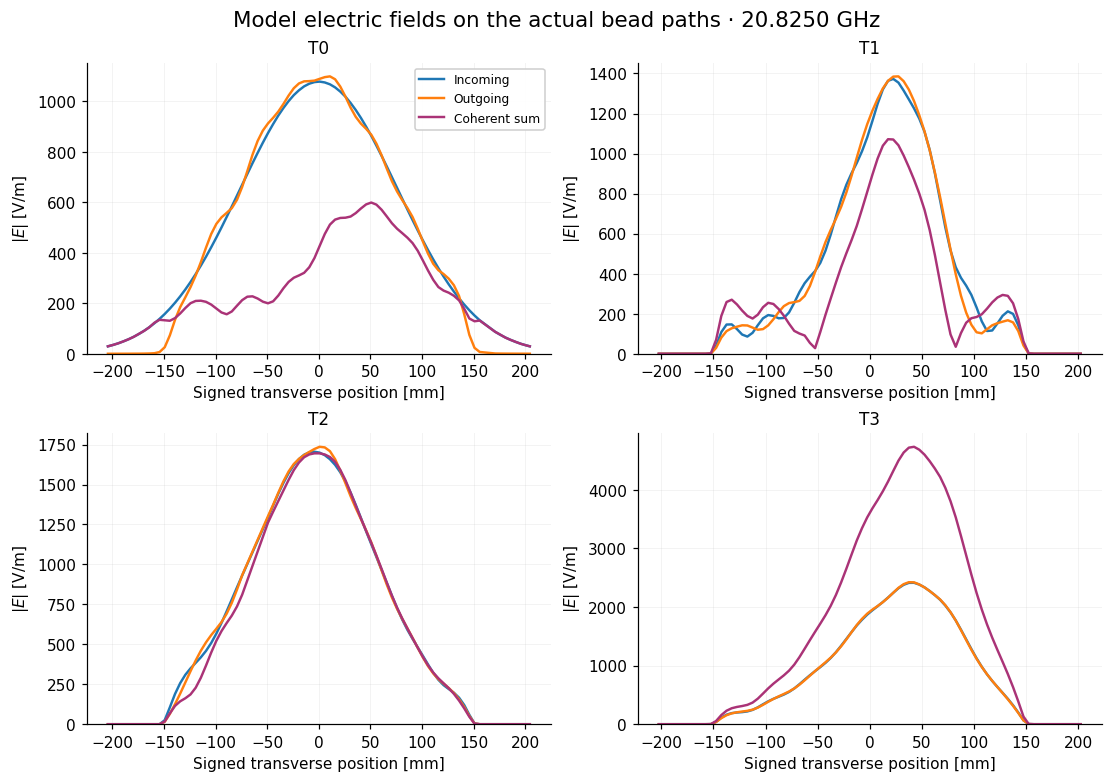

In [14]:
plots.present(
    diagnostics.directional_field_figure(
        result, FREQUENCY_GHZ,
        title='Model electric fields on the actual bead paths · {frequency_GHz:.4f} GHz',
        x_label='Signed transverse position [mm]', y_label='$|E|$ [V/m]',
        thread_label_template='T{thread_index}', incoming_label='Incoming',
        outgoing_label='Outgoing', total_label='Coherent sum',
    ),
    FIGURE_DIR / 'fields/chords',
)

### Electric-field spectra along the sloped paths

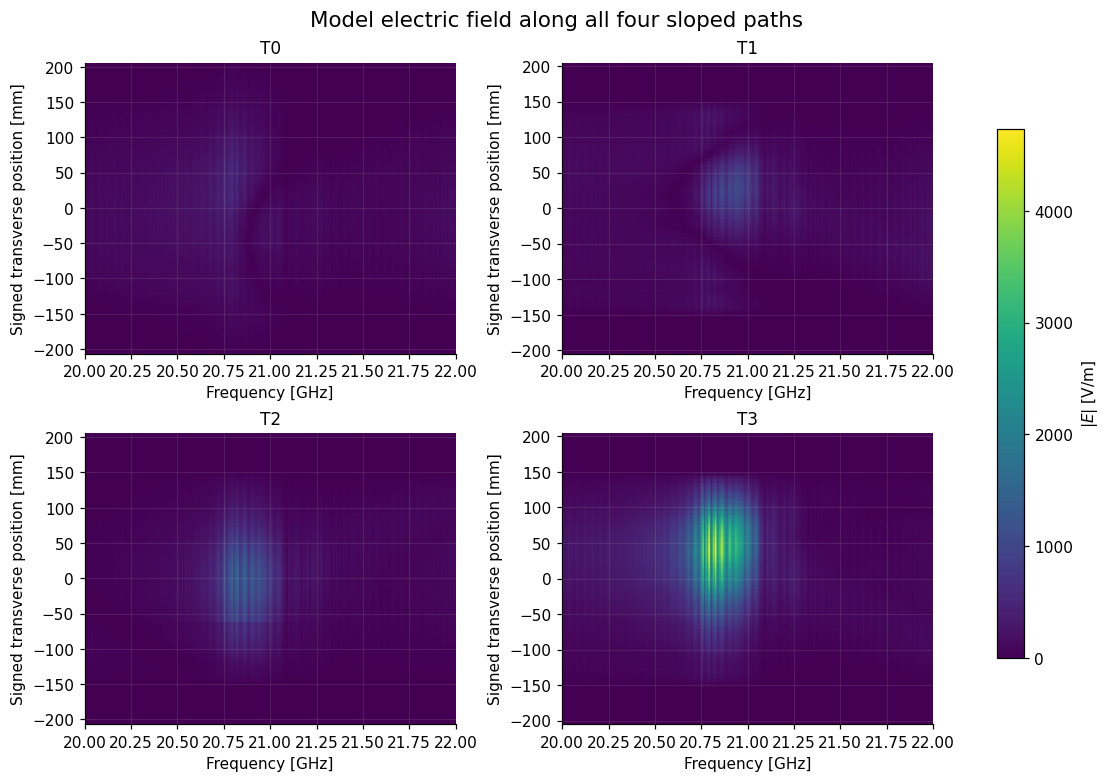

In [15]:
plots.present(
    diagnostics.field_spectrum_figure(
        result,
        title='Model electric field along all four sloped paths',
        x_label='Frequency [GHz]', y_label='Signed transverse position [mm]',
        colorbar_label='$|E|$ [V/m]', thread_label_template='T{thread_index}',
    ),
    FIGURE_DIR / 'fields/spectra',
)

### Horizontal model sections

Fitted and nominal geometries use the same colour scale. Nominal means measured disk positions and tilts, fixed curved faces, and horizontal threads at their nominal z; its common response scale is determined separately from the spider data.

In [ ]:
from src.analysis_3d_exports import nominal_midpoint_maps

NOMINAL_DATA = DATA / 'nominal_geometry'
REBUILD_NOMINAL = False
if REBUILD_NOMINAL or not (NOMINAL_DATA / 'field_maps.npz').exists():
    nominal_midpoint_maps(
        DATA / 'bank', DATA / 'measurement_inputs.npz', DATA / 'beam_prior.npz',
        geometry, NOMINAL_DATA, frequencies_hz=(FREQUENCY_GHZ * 1e9,),
    )

nominal_maps = plots.load(NOMINAL_DATA / 'field_maps.npz')
nominal_result = plots.load(NOMINAL_DATA / 'disk_tilts_threads.npz')
nominal_geometry = json.loads((NOMINAL_DATA / 'disk_tilts_threads.json').read_text())
field_vmax = max(plots.field_map_vmax(maps), plots.field_map_vmax(nominal_maps))

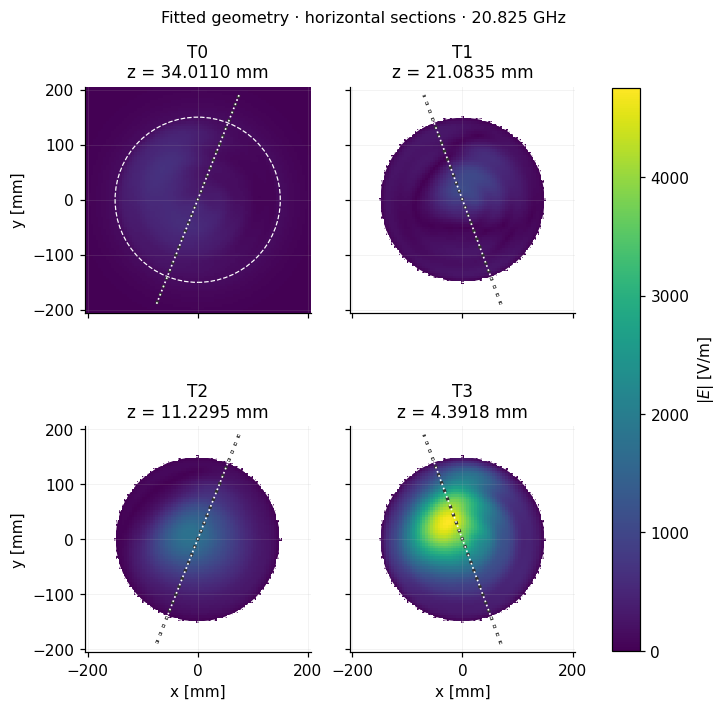

In [16]:
plots.present(
    plots.field_map_figures(
        maps, result, geometry,
        title_template='Fitted geometry · horizontal sections · {frequency_GHz:.3f} GHz',
        panel_title_template='T{thread_index}{held_out}\nz = {z_mm:.4f} mm',
        x_label='x [mm]',
        y_label='y [mm]',
        colorbar_label='$|E|$ [V/m]',
        held_out_label=' · held out',
        vmax=field_vmax,
    ),
    FIGURE_DIR / 'fields/transverse',
)

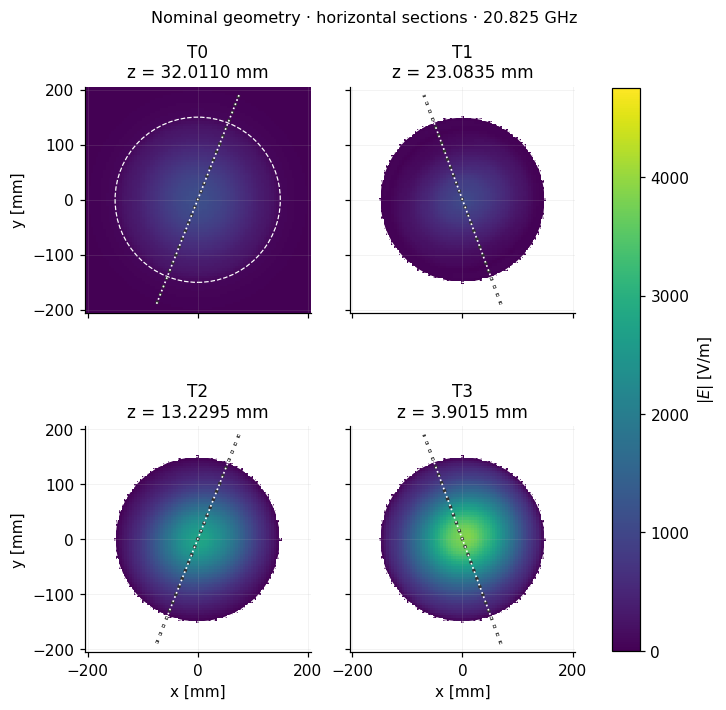

In [ ]:
plots.present(
    plots.field_map_figures(
        nominal_maps, nominal_result, nominal_geometry,
        title_template='Nominal geometry · horizontal sections · {frequency_GHz:.3f} GHz',
        panel_title_template='T{thread_index}{held_out}\nz = {z_mm:.4f} mm',
        x_label='x [mm]',
        y_label='y [mm]',
        colorbar_label='$|E|$ [V/m]',
        held_out_label=' · held out',
        vmax=field_vmax,
    ),
    FIGURE_DIR / 'fields/transverse/nominal',
)

### Nominal geometry: predicted reflection change

Magnitude of the bead-induced $\Delta\Gamma$, including the finite-bead response and the nominal geometry's fitted common scale. The affine background is excluded.

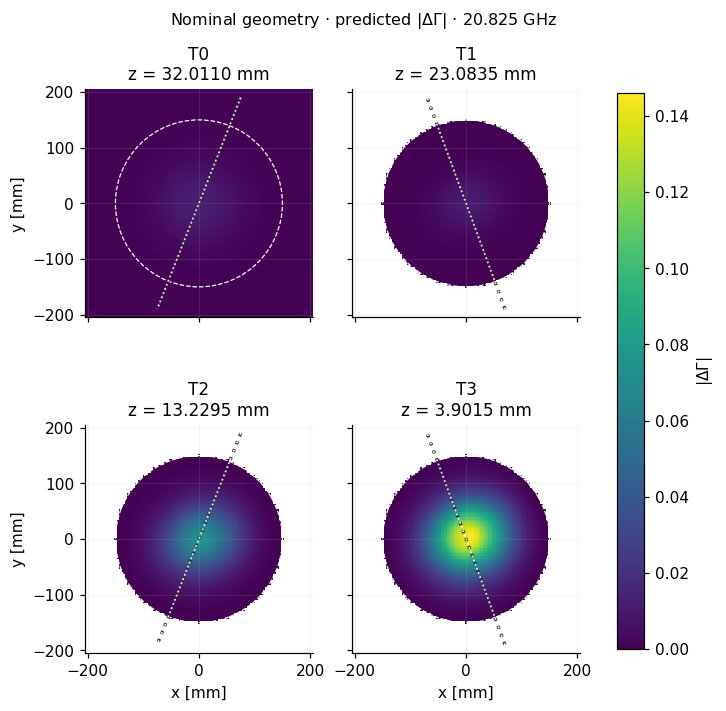

In [ ]:
plots.present(
    plots.field_map_figures(
        nominal_maps, nominal_result, nominal_geometry,
        observable='delta_gamma',
        title_template=r'nominal geometry · modeled $|\Delta\Gamma_s|$ · {frequency_GHz:.3f} GHz',
        panel_title_template='T{thread_index}{held_out}\nz = {z_mm:.4f} mm',
        x_label='x [mm]',
        y_label='y [mm]',
        colorbar_label=r'$|\Delta\Gamma_s|$',
        held_out_label=' · held out',
    ),
    FIGURE_DIR / 'fields/transverse/nominal',
)

## 7. Geometry

Measured curved disk faces are fixed; rigid shifts, tilts and straight-path endpoint heights are fitted. A/B are the retained scan endpoints.

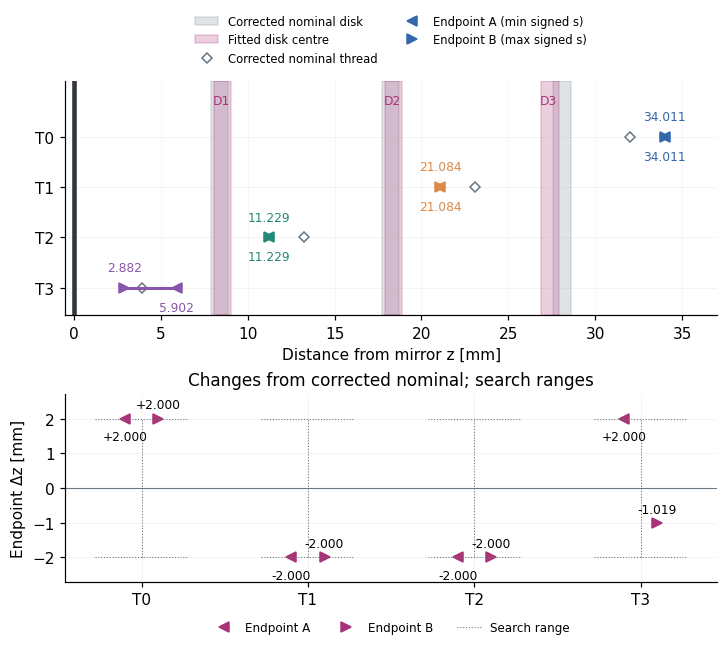

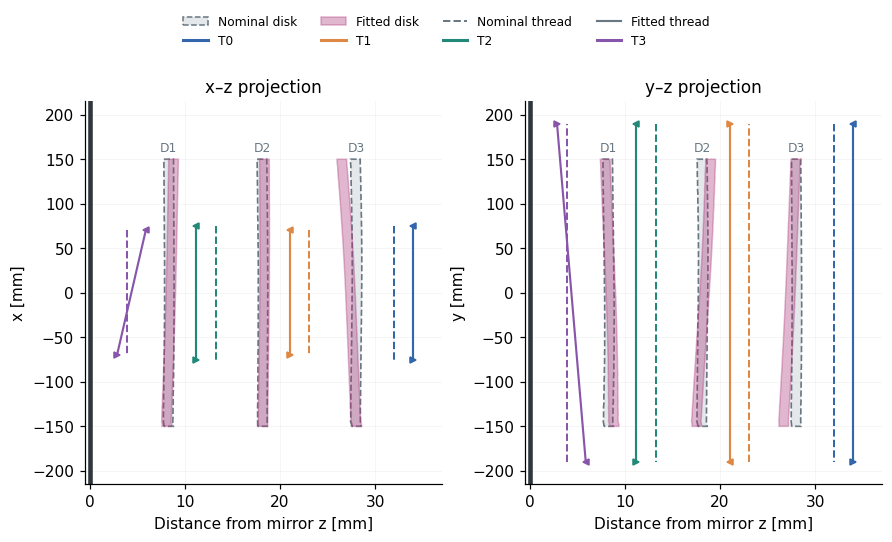

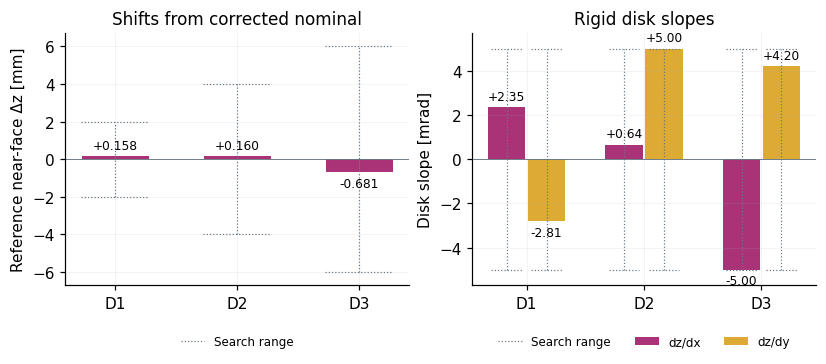

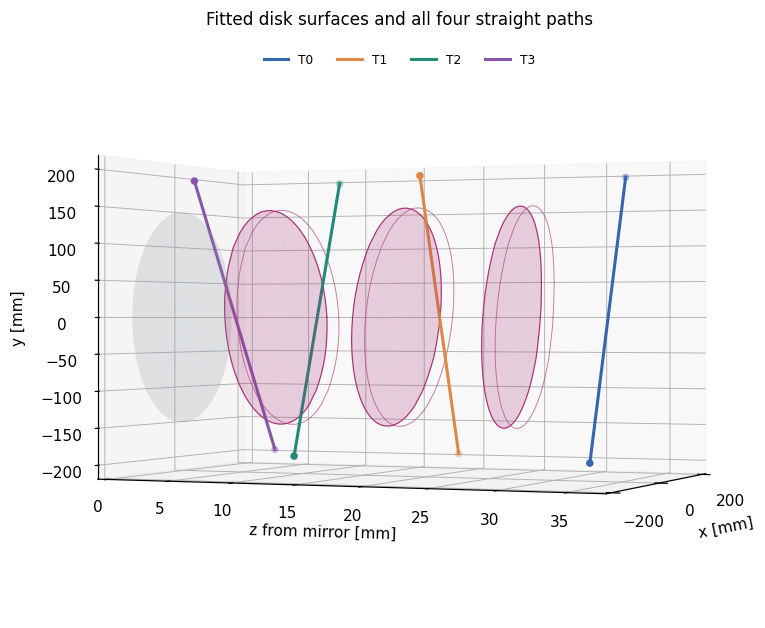

In [17]:
plots.present(
    plots.geometry_figures(
        geometry,
        # endpoint_positions_title='Endpoint heights and central disk positions',
        endpoint_positions_title='',
        endpoint_shifts_title='Changes from corrected nominal; search ranges',
        projection_title_template='{coordinate}–z projection',
        disk_shifts_title='Shifts from corrected nominal',
        disk_slopes_title='Rigid disk slopes',
        view_title='Fitted disk surfaces and all four straight paths',
        z_label='Distance from mirror z [mm]',
        transverse_label_template='{coordinate} [mm]',
        endpoint_shift_y_label='Endpoint Δz [mm]',
        disk_shift_y_label='Reference near-face Δz [mm]',
        disk_slope_y_label='Disk slope [mrad]',
        x_label='x [mm]',
        y_label='y [mm]',
        view_z_label='z from mirror [mm]',
        disk_label_template='D{disk_index}',
        thread_label_template='T{thread_index}',
        position_annotation_template='{z_mm:.3f}',
        shift_annotation_template='{shift_mm:+.3f}',
        slope_annotation_template='{slope_mrad:+.2f}',
        nominal_disk_band_label='Corrected nominal disk',
        fitted_disk_band_label='Fitted disk centre',
        nominal_thread_marker_label='Corrected nominal thread',
        nominal_disk_label='Nominal disk',
        fitted_disk_label='Fitted disk',
        nominal_thread_label='Nominal thread',
        fitted_thread_label='Fitted thread',
        endpoint_a_label='Endpoint A (min signed s)',
        endpoint_b_label='Endpoint B (max signed s)',
        endpoint_shift_label_template='Endpoint {endpoint}',
        search_range_label='Search range',
        slope_x_label='dz/dx',
        slope_y_label='dz/dy',
    ),
    FIGURE_DIR / 'geometry',
)

## 8. Residuals and fitted scales

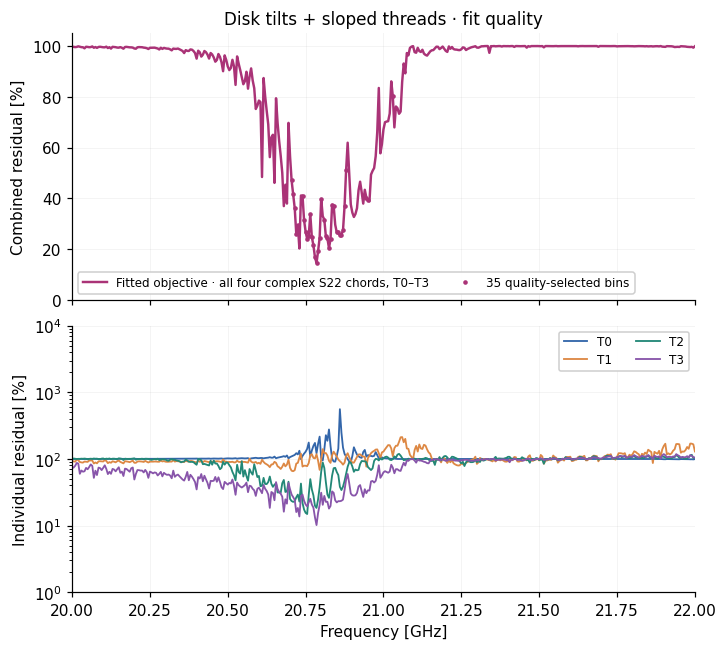

In [18]:
plots.present(
    plots.residual_figure(
        result,
        title_template='{case_title} · fit quality',
        x_label='Frequency [GHz]',
        combined_y_label='Combined residual [%]',
        individual_y_label='Individual residual [%]',
        objective_label_template='Fitted objective · {scope}',
        fit_bins_label_template='{fit_bin_count} quality-selected bins',
        control_label='New fixed-thread tilts · same all-four objective',
        thread_label_template='T{thread_index}{held_out}',
        held_out_label=' · held out',
    ),
    FIGURE_DIR / 'residuals',
)

### Spatial residual maps

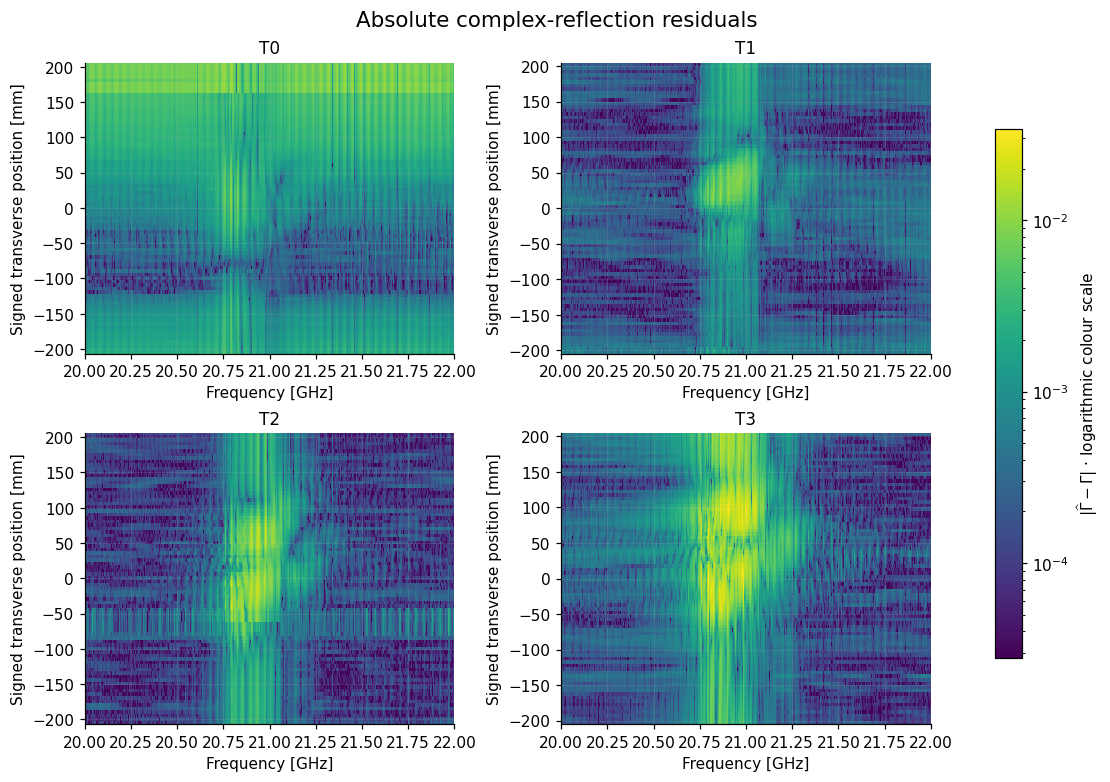

In [19]:
plots.present(
    diagnostics.residual_map_figure(
        result,
        title='Absolute complex-reflection residuals',
        x_label='Frequency [GHz]', y_label='Signed transverse position [mm]',
        colorbar_label=r'$|\widehat\Gamma-\Gamma|$ · logarithmic colour scale',
        thread_label_template='T{thread_index}',
    ),
    FIGURE_DIR / 'residuals/maps',
)

### Absolute signal and residual strength

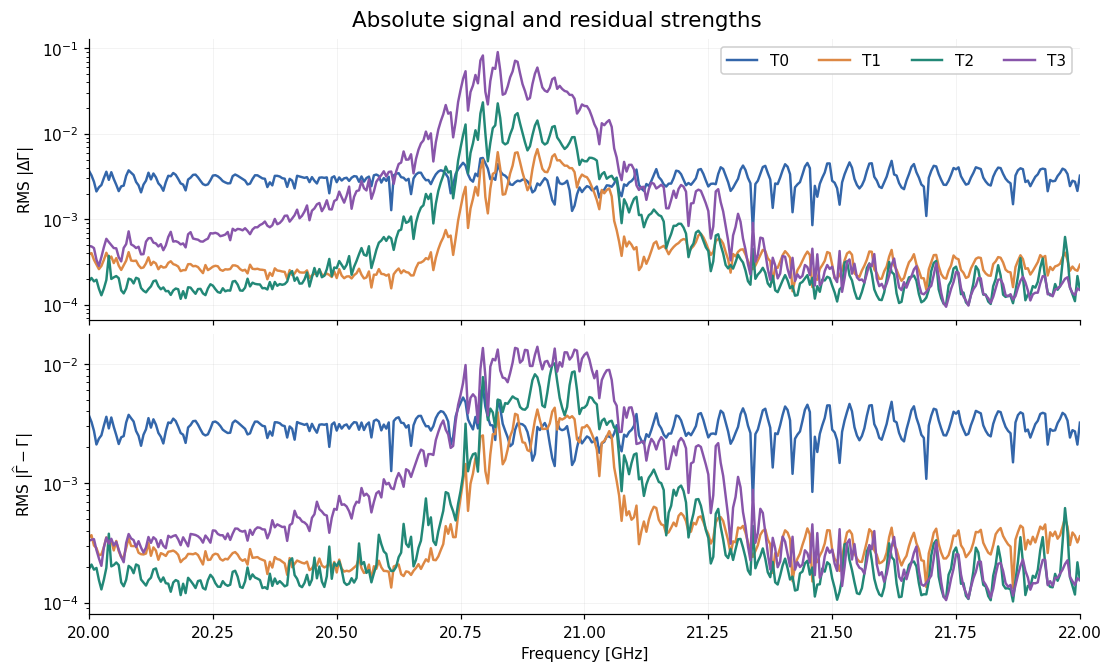

In [20]:
plots.present(
    diagnostics.signal_strength_figure(
        result,
        title='Absolute signal and residual strengths',
        x_label='Frequency [GHz]', signal_y_label=r'RMS $|\Delta\Gamma|$',
        residual_y_label=r'RMS $|\widehat\Gamma-\Gamma|$', thread_label_template='T{thread_index}',
    ),
    FIGURE_DIR / 'residuals/strength',
)

### Common scale and fitted backgrounds

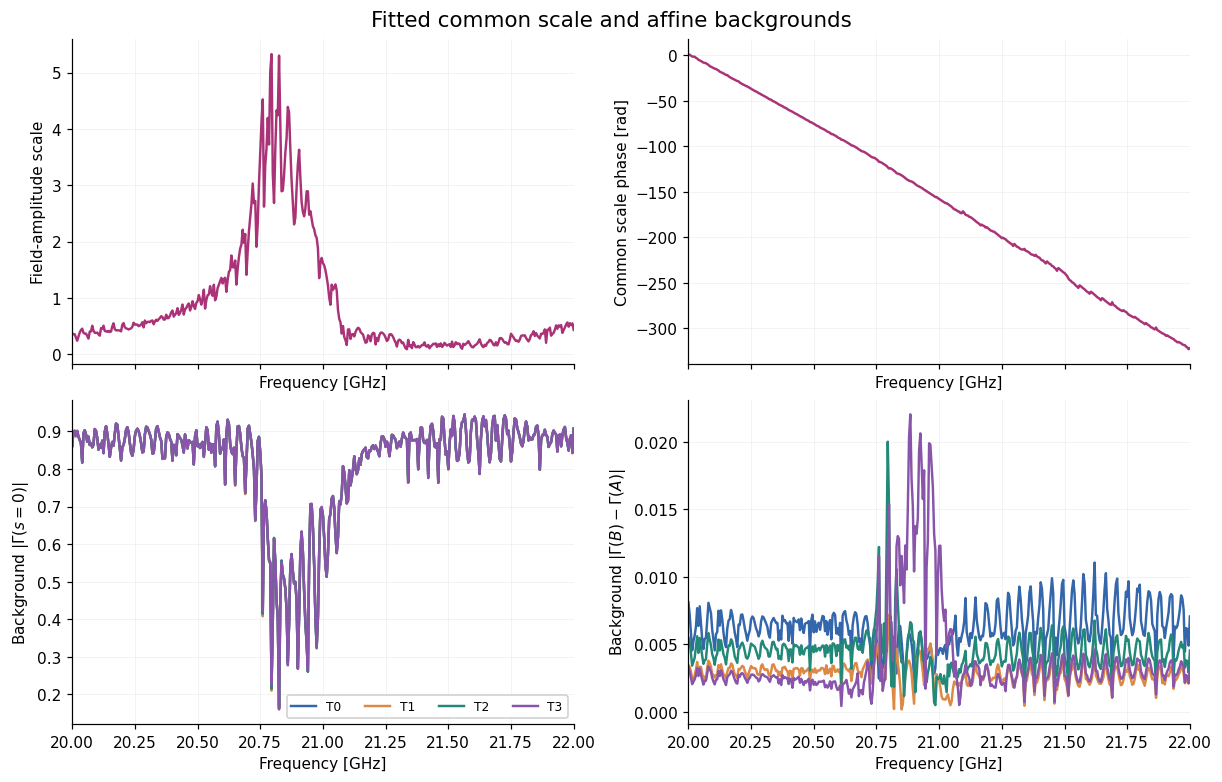

In [21]:
plots.present(
    diagnostics.scale_background_figure(
        result,
        title='Fitted common scale and affine backgrounds',
        x_label='Frequency [GHz]', amplitude_y_label='Field-amplitude scale',
        phase_y_label='Common scale phase [rad]', intercept_y_label=r'Background $|\Gamma(s=0)|$',
        slope_y_label=r'Background $|\Gamma(B)-\Gamma(A)|$', thread_label_template='T{thread_index}',
    ),
    FIGURE_DIR / 'profiles/backgrounds',
)

## 9. Full bead-pull comparison

The full reference is used only for these comparisons.

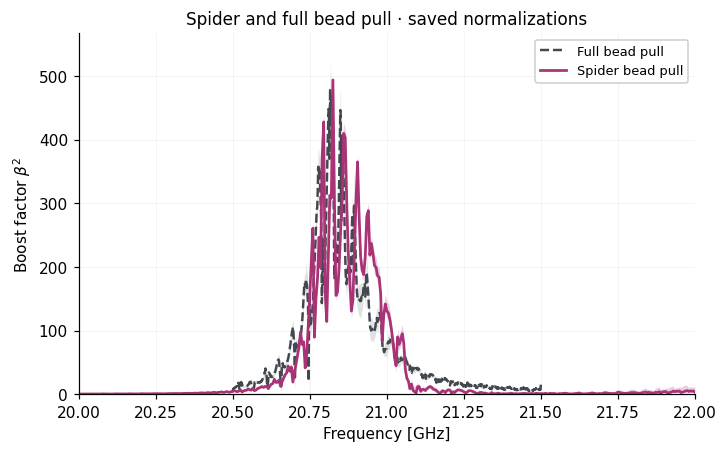

In [22]:
from src.full_bead_comparison import load_full_bead
full = load_full_bead("data/full_bead_pull/result_bf_21_0.jld2")
reference = {"frequency_hz": full.frequencies_Hz, "beta2_saved": full.beta2, "beta2_saved_error": full.beta2_error}
plots.present(
    plots.reference_figure(
        result, bands, reference, "Saved normalizations differ.",
        title='Spider and full bead pull · saved normalizations',
        x_label='Frequency [GHz]',
        y_label='Boost factor $\\beta^2$',
        full_curve_label='Full bead pull',
        spider_curve_label='Spider bead pull',
    ),
    FIGURE_DIR / "full_bead_comparison",
)

### Transverse field integrals

Top: finite-bead field and measured/line-derived estimates. Bottom: model field without the bead. Spider points use the same radial reconstruction as the 1D plots, placed at fitted thread midpoints. They are diagnostics, not 3D fit inputs; horizontal model sections differ from sloped measurement paths.

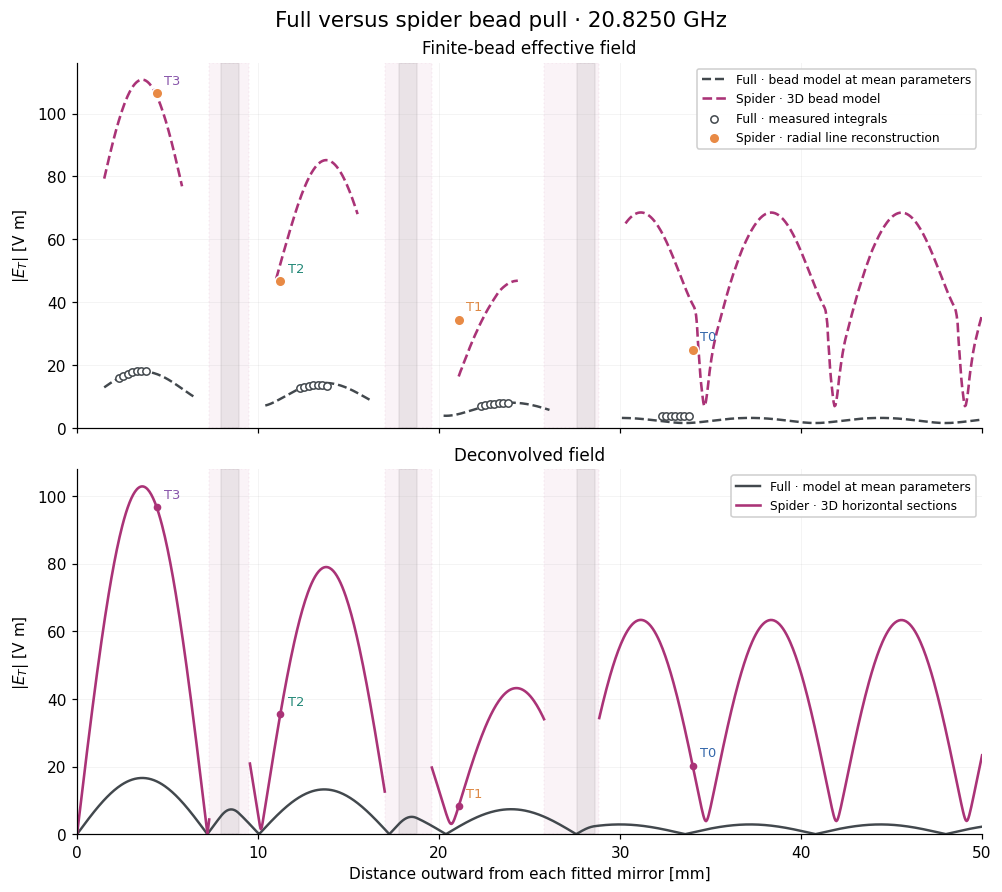

In [23]:
from src.analysis_3d_exports import longitudinal_field_integrals, measured_transverse_integrals
from src.full_bead_comparison import field_reference

sections = longitudinal_field_integrals(
    result, DATA / "bank", DATA / "beam_prior.npz", FREQUENCY_GHZ,
)
np.savez_compressed(DATA / "longitudinal_field_integrals.npz", **sections)
field_reference_data = field_reference(full, FREQUENCY_GHZ)
spider_field_estimates = measured_transverse_integrals(RUN_DIR, FREQUENCY_GHZ)
plots.present(
    plots.reference_field_figure(
        sections, field_reference_data,
        spider_estimates=spider_field_estimates,
        frequency_GHz=FREQUENCY_GHZ,
        title_template='Full versus spider bead pull · {frequency_GHz:.4f} GHz',
        x_label='Distance outward from each fitted mirror [mm]',
        y_label='$|E_T|$ [V m]',
        effective_field_title='Finite-bead effective field',
        deconvolved_field_title='Deconvolved field',
        full_bead_label='Full · bead model at mean parameters',
        spider_bead_label='Spider · 3D bead model',
        full_measured_label='Full · measured integrals',
        spider_measured_label='Spider · radial line reconstruction',
        full_curve_label='Full · model at mean parameters',
        spider_curve_label='Spider · 3D horizontal sections',
        thread_label_template='T{thread_index}',
    ),
    FIGURE_DIR / "full_bead_comparison",
)

## 10. Reprocess measurements (optional)

Set `REPROCESS=True` when ready. Frequencies outside 20–22 GHz are discarded before profile fitting; measured S22 is retained unchanged; beam samples are restricted before interpolation.

In [24]:
from src.analysis_3d_inputs import prepare_measurement, prepare_beam

REPROCESS = False
if REPROCESS:
    prepare_measurement(RUN_DIR, DATA / "measurement_inputs.npz")
    prepare_beam("data/reference_data/beam_measurements/beam_fit_S31.csv",
                 DATA / "beam_prior.npz", result["frequency_hz"])

## 11. Fit/evaluate (optional)

The local fitting bank has all 35 quality-selected frequencies. `data/3d/bank_full401` provides the dense 401-bin evaluation. The optional fitting cell below uses one start.

In [25]:
from src.analysis_3d import EndpointFitProblem, fit_full_tilt, save_result

EVALUATE_MODEL = False
RUN_FIT = False
if EVALUATE_MODEL or RUN_FIT:
    problem = EndpointFitProblem(DATA / "bank", DATA / "measurement_inputs.npz", DATA / "beam_prior.npz")
    parameters = np.asarray(geometry["parameters"])
    details = {"operation": "evaluation of saved geometry"}
    if RUN_FIT:
        # Start from measured central positions and measured relative disk slopes.
        initial = np.zeros(17)
        initial[3:9] = np.asarray(geometry["nominal_disk_slopes_mrad"]).ravel()
        optimization = fit_full_tilt(problem, initial, maxiter=180)
        parameters = optimization.x
        details = {"success": bool(optimization.success), "message": str(optimization.message),
                   "iterations": int(optimization.nit), "starts": 1, "geometry_refitted": True}
    record, evaluated = save_result(problem, parameters, "outputs/sbp_3d", details)

## 12. Export bands and maps (optional)

Requires the preceding evaluation. Bootstrap keeps geometry and illumination fixed.

In [26]:
from src.analysis_3d_exports import conditional_bands, midpoint_maps

EXPORT = False
if EXPORT:
    quantiles = conditional_bands(evaluated, problem.fit_threads, draws=1000)
    np.savez_compressed("outputs/sbp_3d/conditional_bands.npz", frequency_hz=evaluated["frequency_hz"],
                       quantiles=quantiles, quantile_probabilities=[.025, .16, .5, .84, .975])
    midpoint_maps(problem, parameters, "outputs/sbp_3d", frequencies_hz=[FREQUENCY_GHZ * 1e9])